# 01 · Data: four regions → clean 15-minute tables and the train / validation / test split

| Region | Load | Power cuts | Solar + temperature | Role |
|---|---|---|---|---|
| Mathura | CEEW smart meters (3-min) | same meters (voltage < 50 V) | NASA POWER | train + validation |
| Bareilly | CEEW smart meters | same meters | NASA POWER | train + validation |
| Uttar Pradesh | Prayas eMARC main-line meters (15-min) | Prayas ESMI minute voltage | NASA POWER (Lucknow) | train + validation |
| **Pune** | Prayas eMARC (Pune city) | Prayas ESMI (Pune district) | NASA POWER (Pune) | **test only** |

Rules are fixed in `results/FINAL_SPEC.md` (locked in notebook 00). Pune is only turned into tables here; no model sees it until notebook 07.

In [1]:
import json, hashlib, datetime, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, OUT, RES = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True); (RES / "figures").mkdir(parents=True, exist_ok=True)
assert hashlib.sha256((RES / "FINAL_SPEC.md").read_bytes()).hexdigest() == json.loads((RES / "FINAL_SPEC_lock.json").read_text())["sha256"], "plan changed after lock"
SPD, MIN_SLOTS, NO_SUPPLY_V, PR = 96, 90, 50, 0.75
REG = {
    "Mathura":  dict(kind="ceew", lat=27.49, lon=77.67, nasa=["Mathura_2019", "Mathura_2020", "Mathura_2021"],
                     train=("2019-05-01", "2020-08-31"), val=("2020-09-01", "2021-02-20")),
    "Bareilly": dict(kind="ceew", lat=28.37, lon=79.43, nasa=["Bareilly_2019", "Bareilly_2020", "Bareilly_2021"],
                     train=("2019-07-16", "2020-12-31"), val=("2021-01-01", "2021-10-31")),
    "UP":       dict(kind="emarc", lat=26.85, lon=80.95, nasa=["UP3_Lucknow_2019"], year=2019, homes=["Kanpur rural", "Gonda"],
                     esmi=["ESMI voltage data 2019 Jan-June.csv", "ESMI voltage data 2019 July-Dec.csv"], date_fmt="%m/%d/%Y",
                     train=("2019-03-15", "2019-09-30"), val=("2019-10-01", "2019-12-31")),
    "Pune":     dict(kind="emarc", lat=18.52, lon=73.86, nasa=["Pune_2018"], year=2018, homes=["Pune city"],
                     esmi=["ESMI minute-wise voltage data 2018 Jan-May.csv", "ESMI minute-wise voltage data 2018 June-Aug.csv",
                           "ESMI minute-wise voltage data 2018 Sep-Dec.csv"], date_fmt="%d-%m-%Y", test=("2018-01-15", "2018-12-31")),
}
T = {}            # tables per region
report = {}
print("plan verified | regions:", list(REG))

plan verified | regions: ['Mathura', 'Bareilly', 'UP', 'Pune']


## 1. CEEW smart meters (Mathura, Bareilly)
Cut = at least half of a slot's 3-minute readings below 50 V. Demand during a cut = the home's mean supplied load at the same slot
in the same month (fallback: same slot, all months). Homes with < 20% coverage over their span are excluded.

In [2]:
def ceew(city):
    parts = []
    for y in [2019, 2020, 2021]:
        df = pd.read_csv(RAW / "ceew" / f"{city}_{y}.csv", usecols=["x_Timestamp", "t_kWh", "z_Avg Voltage (Volt)", "meter"])
        df.columns = ["ts", "kwh", "v", "meter"]; df["ts"] = pd.to_datetime(df.ts); parts.append(df)
    df = pd.concat(parts, ignore_index=True).drop_duplicates(["meter", "ts"])
    df = df.assign(off=df.v < NO_SUPPLY_V, slot=df.ts.dt.floor("15min"))
    s = df.groupby(["meter", "slot"]).agg(n=("v", "size"), n_off=("off", "sum"), kwh=("kwh", "sum")).reset_index()
    del df
    s["cut"] = (s.n_off / s.n >= 0.5).astype(float); s["load_kw"] = s.kwh / 0.25
    idx = pd.date_range(s.slot.min(), s.slot.max(), freq="15min")
    cut = s.pivot(index="slot", columns="meter", values="cut").reindex(idx)
    load = s.pivot(index="slot", columns="meter", values="load_kw").reindex(idx)
    k = np.asarray(idx.hour * 4 + idx.minute // 15); month = np.asarray(idx.year * 12 + idx.month)
    sup = load.where(cut == 0)
    demand = sup.fillna(sup.groupby([month, k]).transform("mean")).fillna(sup.groupby(k).transform("mean"))
    ok_day = cut.notna().groupby(idx.normalize()).sum() >= MIN_SLOTS
    cov = {}
    for m in cut.columns:
        x = cut[m]; span = x.loc[x.first_valid_index():x.last_valid_index()]; cov[m] = span.notna().mean()
    low = [m for m, c in cov.items() if c < 0.20]
    ok_day.loc[:, low] = False
    report[city] = {"homes": int(cut.shape[1]), "excluded_low_coverage": low, "from": str(idx[0]), "to": str(idx[-1]),
                    "cut_h_per_home_day": float(np.nanmean(cut.values) * 24)}
    return {"cut": cut, "demand": demand, "supplied_load": sup, "ok_day": ok_day}

t0 = time.time()
for c in ["Mathura", "Bareilly"]:
    T[c] = ceew(c); print(f"{c}: {T[c]['cut'].shape[1]} homes, {T[c]['cut'].shape[0]:,} slots | cut {report[c]['cut_h_per_home_day']:.2f} h/home/day | excluded {report[c]['excluded_low_coverage']} ({time.time() - t0:.0f}s)")

Mathura: 38 homes, 63,552 slots | cut 2.19 h/home/day | excluded [] (12s)


Bareilly: 46 homes, 87,072 slots | cut 1.68 h/home/day | excluded [] (32s)


## 2. eMARC load + ESMI cuts (Uttar Pradesh 2019, Pune 2018)
- **Load:** main-line meters; blocks < 1 W are unknown (cut or no use cannot be told apart) and filled with home × month × slot mean,
  then home × slot mean, then the home's mean. Complete home-day: ≥ 90 of 96 blocks present in the file.
- **Cuts:** ESMI minute voltage; a 15-minute slot is cut if at least half of its present minutes are < 50 V (< 8 minutes present → supply on).
  Site-days whose Hour column is broken: rebuilt from row order when the site-day has exactly 24 rows, otherwise dropped (v3 rule).
- **Pairing:** Uttar Pradesh exactly as v3 (scenario A). Pune: domestic Pune-district sites with ≥ 300 days of data and ≥ 0.5 cut h/day;
  homes in random order (seed 0), round-robin over the sites.

In [3]:
info = pd.read_excel(RAW / "emarc" / "Household-Deployment basic info.xlsx")
LB = pd.read_csv(RAW / "emarc" / "eMARC load blocks.csv", encoding="utf-8-sig")
LOC = pd.read_csv(RAW / "esmi" / "ESMI location information.csv", encoding="utf-8-sig")
MINS = [f"Min {i}" for i in range(60)]

def emarc_load(r):
    R = REG[r]; IDX = pd.date_range(f"{R['year']}-01-01", f"{R['year']}-12-31 23:45", freq="15min")
    up = info[info.Region.isin(R["homes"]) & (info["Deployment type"] == "Mainline")]
    lb = LB[LB.deployment_id.isin(up.deployment_id)].copy()
    lb["ts"] = pd.to_datetime(lb["date"], format="%m/%d/%Y") + pd.to_timedelta(lb["block"] * 15, unit="min")
    lb = lb[(lb.ts >= IDX[0]) & (lb.ts <= IDX[-1])].drop_duplicates(["deployment_id", "ts"])
    lb["home"] = lb.deployment_id.map(dict(zip(up.deployment_id, up.household_id)))
    raw = lb.pivot_table(index="ts", columns="home", values="Load (kW)", aggfunc="mean").reindex(IDX)
    known = raw.where(raw >= 0.001)
    k = np.asarray(IDX.hour * 4 + IDX.minute // 15); month = np.asarray(IDX.month)
    demand = known.fillna(known.groupby([month, k]).transform("mean")).fillna(known.groupby(k).transform("mean")).fillna(known.mean())
    ok_day = raw.notna().groupby(IDX.normalize()).sum() >= MIN_SLOTS
    return IDX, known, demand, ok_day, dict(zip(up.household_id, up.Region))

def esmi_cuts(r, sites):
    R = REG[r]; parts, repaired, dropped = [], 0, 0
    for f in R["esmi"]:
        x = pd.read_csv(RAW / "esmi" / f, encoding="utf-8-sig", low_memory=False)
        x = x[x["Location name"].isin(sites)].copy()
        grp = x.groupby(["Location name", "Date"])
        broken = grp["Hour"].transform(lambda s: not s.is_unique); size = grp["Hour"].transform("size")
        x.loc[broken & (size == 24), "Hour"] = x[broken & (size == 24)].groupby(["Location name", "Date"]).cumcount().values
        repaired += int((broken & (size == 24)).sum()); dropped += int((broken & (size != 24)).sum())
        x = x[~(broken & (size != 24))]
        d = pd.to_datetime(x["Date"], format=R["date_fmt"], errors="coerce")
        parts.append(x.assign(ts=d + pd.to_timedelta(pd.to_numeric(x["Hour"], errors="coerce"), unit="h")).dropna(subset=["ts"]))
    e = pd.concat(parts).drop_duplicates(["Location name", "ts"])
    V = e[MINS].apply(pd.to_numeric, errors="coerce").to_numpy(); rows = []
    for q in range(4):
        blk = V[:, q * 15:(q + 1) * 15]; n_p = np.isfinite(blk).sum(1); n_low = (blk < 50).sum(1)
        rows.append(pd.DataFrame({"site": e["Location name"].values, "ts": e.ts.values + np.timedelta64(15 * q, "m"),
                                  "cut": np.where(n_p >= 8, (n_low >= n_p / 2).astype(float), np.nan)}))
    IDX = pd.date_range(f"{R['year']}-01-01", f"{R['year']}-12-31 23:45", freq="15min")
    cs = pd.concat(rows).pivot_table(index="ts", columns="site", values="cut", aggfunc="first").reindex(IDX)
    return cs, repaired, dropped

def finish(r, IDX, known, demand, ok_day, cs, assign):
    homes = list(known.columns)
    cut = pd.DataFrame({h: cs[assign[h]].values for h in homes}, index=IDX)     # NaN = no ESMI data -> supply on in the simulator
    T[r] = {"cut": cut, "demand": demand, "supplied_load": known.where(cut == 0), "ok_day": ok_day}

# ---- Uttar Pradesh (v3 pairing, scenario A) ----
IDX, known, demand, ok_day, region_of = emarc_load("UP")
cand = LOC[(LOC.State == "Uttar Pradesh") & LOC.District.isin(["Kanpur", "Bahraich", "Barabanki"]) & (LOC["Connection Type"] == "Domestic")]
cs, rep, drop = esmi_cuts("UP", cand["Location name"])
days = (cs.notna().groupby(IDX.normalize()).sum() > 0).sum(); pool = sorted(days[days >= 300].index)
dist = cand.set_index("Location name").District
rng = np.random.default_rng(0)
kan = [s for s in pool if dist[s] == "Kanpur"]; gon = list(rng.permutation([s for s in pool if dist[s] in ("Bahraich", "Barabanki")]))
assign, gi = {}, 0
for h in known.columns:
    if region_of[h] == "Kanpur rural": assign[h] = kan[0]
    else: assign[h] = gon[gi % len(gon)]; gi += 1
finish("UP", IDX, known, demand, ok_day, cs, assign)
report["UP"] = {"homes": len(assign), "sites": pool, "site_use": pd.Series(assign).value_counts().to_dict(), "hour_rebuilt_rows": rep,
                "broken_rows_dropped": drop, "cut_h_per_home_day": float(T["UP"]["cut"].mean().mean() * 24)}
print("UP:", json.dumps(report["UP"], default=str))

# ---- Pune (test region) ----
IDX, known, demand, ok_day, _ = emarc_load("Pune")
cand = LOC[(LOC.State == "Maharashtra") & (LOC.District == "Pune") & (LOC["Connection Type"] == "Domestic")]
cs, rep, drop = esmi_cuts("Pune", cand["Location name"])
days = (cs.notna().groupby(IDX.normalize()).sum() > 0).sum()
cuth = cs.mean() * 24
sites = sorted(s for s in cs.columns if days[s] >= 300 and cuth[s] >= 0.5)
order = list(np.random.default_rng(0).permutation(list(known.columns)))
assign = {h: sites[i % len(sites)] for i, h in enumerate(order)}
finish("Pune", IDX, known, demand, ok_day, cs, assign)
report["Pune"] = {"homes": len(assign), "sites": sites, "site_days": {s: int(days[s]) for s in sites}, "site_cut_h_per_day": {s: round(float(cuth[s]), 2) for s in sites},
                  "site_use": pd.Series(assign).value_counts().to_dict(), "hour_rebuilt_rows": rep, "broken_rows_dropped": drop}
print("Pune:", json.dumps(report["Pune"], default=str))

UP: {"homes": 36, "sites": ["Awas Vikas colony Barabanki", "Bardaha-Bahraich", "Kanoongopura Bahraich", "Masvanpur-Kanpur"], "site_use": {"Masvanpur-Kanpur": 19, "Kanoongopura Bahraich": 6, "Awas Vikas colony Barabanki": 6, "Bardaha-Bahraich": 5}, "hour_rebuilt_rows": 24528, "broken_rows_dropped": 29775, "cut_h_per_home_day": 2.332413748879842}


Pune: {"homes": 44, "sites": ["Kondhanpur", "Paud", "Talegaon"], "site_days": {"Kondhanpur": 365, "Paud": 343, "Talegaon": 348}, "site_cut_h_per_day": {"Kondhanpur": 1.32, "Paud": 1.33, "Talegaon": 0.63}, "site_use": {"Kondhanpur": 15, "Paud": 15, "Talegaon": 14}, "hour_rebuilt_rows": 0, "broken_rows_dropped": 0}


## 3. Solar and temperature (NASA POWER hourly → +30 min → IST; 15-minute series and a causal hourly series)

In [4]:
for r, R in REG.items():
    g, t2 = {}, {}
    for f in R["nasa"]:
        p = json.loads((RAW / "nasa" / f"{f}.json").read_text())["properties"]["parameter"]; g.update(p["ALLSKY_SFC_SW_DWN"]); t2.update(p["T2M"])
    h = pd.DataFrame({"ghi": pd.Series(g), "t2m": pd.Series(t2)}).replace(-999.0, np.nan)
    h.index = pd.to_datetime(h.index, format="%Y%m%d%H") + pd.Timedelta(minutes=30) + pd.Timedelta(hours=5, minutes=30)
    q = h.resample("15min").mean().interpolate(limit=8).clip(lower=0); q["pv_kw_per_kwp"] = q.ghi / 1000 * PR
    causal = h.copy(); causal.index = causal.index + pd.Timedelta(minutes=30)
    prof = q.groupby(q.index.hour + q.index.minute / 60).pv_kw_per_kwp.mean()
    T[r]["solar"], T[r]["hourly"] = q, causal
    report[r]["solar"] = {"curve_centre_ist_h": round(float((prof.index * prof).sum() / prof.sum()), 2), "solar_noon_ist_h": round(12 - R["lon"] / 15 + 5.5, 2),
                          "kwh_per_kwp_day": round(float(q.pv_kw_per_kwp.resample("D").sum().mean() * 0.25), 2)}
    print(r, report[r]["solar"])

Mathura {'curve_centre_ist_h': 12.29, 'solar_noon_ist_h': 12.32, 'kwh_per_kwp_day': 3.54}


Bareilly {'curve_centre_ist_h': 12.22, 'solar_noon_ist_h': 12.2, 'kwh_per_kwp_day': 3.42}
UP {'curve_centre_ist_h': 12.14, 'solar_noon_ist_h': 12.1, 'kwh_per_kwp_day': 3.43}
Pune {'curve_centre_ist_h': 12.59, 'solar_noon_ist_h': 12.58, 'kwh_per_kwp_day': 3.75}


## 4. Check: Mathura, Bareilly and Uttar Pradesh tables reproduce the archived v1–v3 tables

In [5]:
A = ROOT / "_archive" / "data_processed"
for c in ["Mathura", "Bareilly"]:
    for k in ["cut", "demand", "supplied_load"]:
        old = pd.read_parquet(A / f"{c}_{k}.parquet"); new = T[c][k].astype("float32")
        assert old.shape == new.shape and np.allclose(old.values, new.values, equal_nan=True, atol=1e-6), f"{c} {k} differs from v1"
    old = pd.read_parquet(A / f"{c}_complete_days.parquet").astype(bool); assert old.equals(T[c]["ok_day"].astype(bool)), f"{c} complete days differ"
upa = pd.read_parquet(A / "v3" / "UP3A_cut.parquet")
assert upa.shape == T["UP"]["cut"].shape and np.array_equal(upa.values, T["UP"]["cut"].values.astype("float32"), equal_nan=True), "UP cuts differ from v3"
assert np.allclose(pd.read_parquet(A / "v3" / "UP3_demand.parquet").values, T["UP"]["demand"].astype("float32").values, equal_nan=True)
print("OK: Mathura, Bareilly (v1) and Uttar Pradesh (v3) tables are identical to the archived ones")

OK: Mathura, Bareilly (v1) and Uttar Pradesh (v3) tables are identical to the archived ones


## 5. Split: training windows (sliding), validation and test weeks (non-overlapping, fixed 10 homes, seed 0)
The last 15% (by time) of each region's TRAIN period is the hold-out used for early stopping / calibration (forecasters) and for
choosing the cloning epoch (behaviour cloning).

In [6]:
def pool_at(r, s):
    ok = T[r]["ok_day"].reindex(pd.date_range(s, periods=7, freq="D")).fillna(False).astype(bool)
    return [h for h in ok.columns if bool(ok[h].all())]

split = {"n_homes": 10, "days": 7, "regions": {}, "train": [], "val": [], "test": []}
rng = np.random.default_rng(0)
for r, R in REG.items():
    info_r = {}
    for part in ["train", "val", "test"]:
        if part not in R: continue
        a, b = pd.Timestamp(R[part][0]), pd.Timestamp(R[part][1])
        starts = pd.date_range(a, b - pd.Timedelta(days=6), freq="D" if part == "train" else "7D")
        cut_hold = a + (b - a) * 0.85
        n = 0
        for s in starts:
            p = pool_at(r, s)
            if len(p) < 10: continue
            w = {"region": r, "start": str(s), "pool": p}
            if part == "train": w["hold"] = bool(s >= cut_hold.normalize())
            else: w["homes"] = sorted(rng.choice(p, 10, replace=False).tolist())
            split[part].append(w); n += 1
        info_r[part] = {"from": str(a.date()), "to": str(b.date()), "windows": n, **({"holdout_from": str(cut_hold.normalize().date())} if part == "train" else {})}
    split["regions"][r] = info_r
# scalers: pooled TRAIN periods only
temps, homes_mean = [], []
for r, R in REG.items():
    if "train" not in R: continue
    a, b = pd.Timestamp(R["train"][0]), pd.Timestamp(R["train"][1]) + pd.Timedelta(hours=23, minutes=45)
    temps.append(T[r]["solar"].t2m.loc[a:b]); homes_mean.append(T[r]["supplied_load"].loc[a:b].mean())
tt = pd.concat(temps)
split["scalers"] = {"fitted_on": "pooled TRAIN periods (Mathura, Bareilly, Uttar Pradesh)", "temperature_mean": float(tt.mean()),
                    "temperature_std": float(tt.std()), "home_load_fallback_kw": float(pd.concat(homes_mean).median())}
for part in ["train", "val"]:
    for w in split[part]:
        a, b = REG[w["region"]][part]
        assert pd.Timestamp(a) <= pd.Timestamp(w["start"]) and pd.Timestamp(w["start"]) + pd.Timedelta(days=7) <= pd.Timestamp(b) + pd.Timedelta(days=1)
display(pd.DataFrame({r: {f"{p} windows": v["windows"] for p, v in d.items()} for r, d in split["regions"].items()}).T)
print(json.dumps(split["scalers"], indent=1))

,train windows,val windows,test windows
Mathura,374.0,17.0,NaN
Bareilly,486.0,43.0,NaN
UP,120.0,13.0,NaN
Pune,NaN,NaN,50.0


{
 "fitted_on": "pooled TRAIN periods (Mathura, Bareilly, Uttar Pradesh)",
 "temperature_mean": 26.839854217728757,
 "temperature_std": 8.603692770210321,
 "home_load_fallback_kw": 0.29278527847104496
}


## 6. Save tables, the split (locked by hash) and the data report

In [7]:
for r in REG:
    for k in ["cut", "demand", "supplied_load"]:
        T[r][k].astype("float32").to_parquet(OUT / f"{r}_{k}.parquet")
    T[r]["ok_day"].astype(np.int8).to_parquet(OUT / f"{r}_complete_days.parquet")
    T[r]["solar"].astype("float32").to_parquet(OUT / f"{r}_solar_15min.parquet"); T[r]["hourly"].astype("float32").to_parquet(OUT / f"{r}_solar_hourly_causal.parquet")
txt = json.dumps(split, indent=1)
lock = OUT / "split_lock.json"
if lock.exists():
    assert hashlib.sha256(json.dumps(json.loads((OUT / "split.json").read_text()), indent=1).encode()).hexdigest() == json.loads(lock.read_text())["sha256"], "split changed after lock"
else:
    (OUT / "split.json").write_text(txt)
    lock.write_text(json.dumps({"sha256": hashlib.sha256(txt.encode()).hexdigest(), "created": datetime.datetime.now().isoformat(timespec="seconds")}, indent=1))
(RES / "data_report.json").write_text(json.dumps(report, indent=1, default=str))
print("split locked:", json.loads(lock.read_text())["sha256"][:16], "| train", len(split["train"]), "| val", len(split["val"]), "| test", len(split["test"]))

split locked: 56800a6682449874 | train 980 | val 73 | test 50


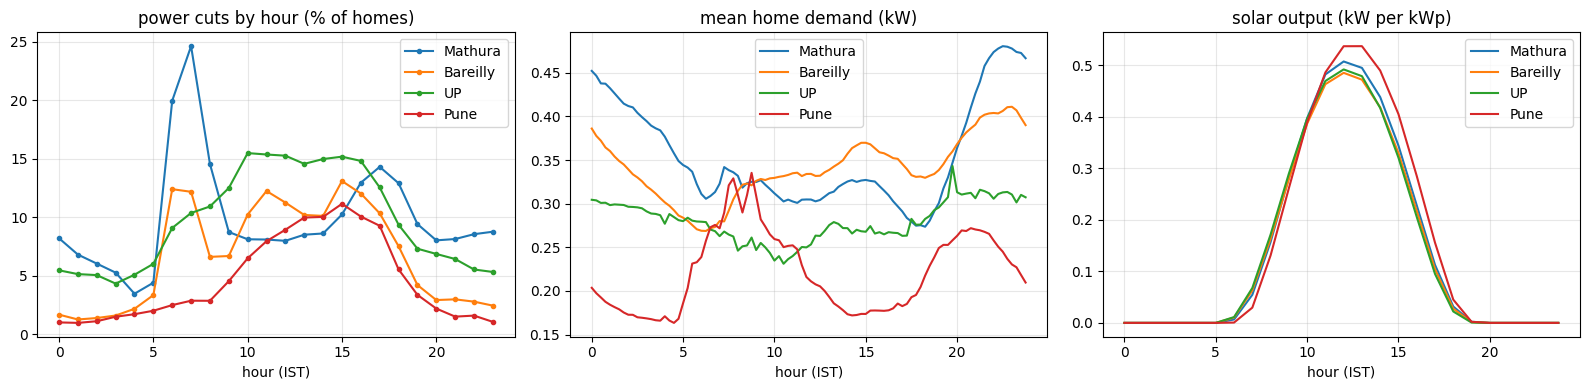

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for r in REG:
    c = T[r]["cut"]; ax[0].plot(range(24), c.groupby(c.index.hour).mean().mean(1) * 100, marker="o", ms=3, label=r)
    d = T[r]["demand"]; ax[1].plot(np.arange(96) / 4, d.groupby(d.index.hour * 4 + d.index.minute // 15).mean().mean(1), label=r)
    q = T[r]["solar"]; ax[2].plot(np.arange(96) / 4, q.groupby(q.index.hour * 4 + q.index.minute // 15).pv_kw_per_kwp.mean().values, label=r)
for a, t in zip(ax, ["power cuts by hour (% of homes)", "mean home demand (kW)", "solar output (kW per kWp)"]):
    a.set_title(t); a.set_xlabel("hour (IST)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(RES / "figures" / "01_data_profiles.png", dpi=130); plt.show()